# NYC Transportation Database and Feature Store
**CSDS 341: Introduction to Database Systems, Final Project**

This project builds a PostgreSQL database of 2024 New York City trips from two public sources, **NYC TLC Yellow Taxi** and **Citi Bike**. It uses the database as a **feature store** for a machine-learning task: predicting whether a trip was taken by **taxi or bike** from its time-based features.

### Pipeline overview

| Stage | Where it happens | Database effect |
|---|---|---|
| 1–3. Download, load and sample raw data | This notebook | None |
| 4. Connect to PostgreSQL | This notebook | None |
| 5. Load samples into staging tables | This notebook | Replaces `taxi_staging`, `bike_staging` |
| 6. Build the normalized schema | `Project/Transportation_Database.sql` (run separately) | Drops and recreates the permanent tables |
| 7. Benchmark feature-store designs | This notebook | Read-only |
| 8. Train and evaluate classifiers | This notebook | Read-only |
| 9. Store predictions | This notebook (**one-time cell**) | Inserts into `prediction`, `prediction_feature` |

> **Before running this notebook:** Database credentials are read from a local `.env` file (`DB_USER`, `DB_PASSWORD`, `DB_HOST`, `DB_PORT`, `DB_NAME`). That file is git-ignored and never printed. The prediction-insertion cell in Section 9.2 has **already been executed** and must not be rerun against the existing database.

<a id="contents"></a>

## Table of Contents

1. [Environment Setup](#sec-1)
    - [1.1 Dependencies](#sec-1-1)
    - [1.2 Imports and Study Period](#sec-1-2)
2. [Data Acquisition](#sec-2)
    - [2.1 NYC Yellow Taxi Trip Records](#sec-2-1)
    - [2.2 Citi Bike Trip Records](#sec-2-2)
3. [Data Loading and Sampling](#sec-3)
    - [3.0 Sample Cache Locations](#sec-3-0)
    - [3.1 Columns Retained](#sec-3-1)
    - [3.2 Yellow Taxi: Loader and Preview](#sec-3-2)
    - [3.3 Yellow Taxi: Monthly Sampling](#sec-3-3)
    - [3.4 Citi Bike: Loader and Preview](#sec-3-4)
    - [3.5 Citi Bike: Monthly Sampling](#sec-3-5)
4. [PostgreSQL Connection](#sec-4)
5. [Loading the Staging Tables](#sec-5)
6. [Building the Normalized Schema (Transportation_Database.sql)](#sec-6)
7. [Feature Store Benchmark: Row-Oriented vs. Wide](#sec-7)
8. [Machine Learning: Predicting Trip Mode](#sec-8)
    - [8.1 Loading the Modeling Dataset](#sec-8-1)
    - [8.2 Data Quality Checks](#sec-8-2)
    - [8.3 Feature Encoding and Train/Test Split](#sec-8-3)
    - [8.4 Model 1: Categorical Naive Bayes](#sec-8-4)
    - [8.5 Model 2: Logistic Regression](#sec-8-5)
    - [8.6 Model Comparison](#sec-8-6)
9. [Storing Predictions in the Database](#sec-9)
    - [9.1 Preparing the Prediction Export](#sec-9-1)
    - [9.2 Inserting Predictions (One-Time Operation)](#sec-9-2)
    - [9.3 Verifying the Stored Predictions](#sec-9-3)
10. [Summary](#sec-10)

---
<a id="sec-1"></a>

## 1. Environment Setup
<sub>[↑ Back to contents](#contents)</sub>

<a id="sec-1-1"></a>

### 1.1 Dependencies
Installs all packages used in the notebook: data download (`requests`), file parsing (`pandas`, `pyarrow`), credential loading (`python-dotenv`), database access (`sqlalchemy`, `psycopg2-binary`), machine learning (`scikit-learn`) and plotting (`matplotlib`).

In [60]:
%pip install pandas pyarrow requests python-dotenv sqlalchemy psycopg2-binary scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


<a id="sec-1-2"></a>

### 1.2 Imports and Study Period
Defines the local data folders and the list of months (January–December 2024) to download.

In [61]:
import os
import zipfile
from io import BytesIO
from datetime import datetime

import pandas as pd
import requests

# Study period: calendar year 2024
START_YEAR = 2024

# Local folders for the raw downloaded files
BASE_DIR = "nyc_transportation_data"

TAXI_DIR = os.path.join(BASE_DIR, "yellow_taxi")
BIKE_DIR = os.path.join(BASE_DIR, "citibike")

os.makedirs(TAXI_DIR, exist_ok=True)
os.makedirs(BIKE_DIR, exist_ok=True)

# Months in the study period (YYYY-MM), excluding any future months
current_date = datetime.now()

months = [
    f"{year}-{month:02d}"
    for year in range(START_YEAR, START_YEAR + 1)
    for month in range(1, 13)
    if (year, month) <= (current_date.year, current_date.month)
]

print(f"Months to process: {len(months)}")
print(f"First month: {months[0]}")
print(f"Last month: {months[-1]}")

Months to process: 12
First month: 2024-01
Last month: 2024-12


---
<a id="sec-2"></a>

## 2. Data Acquisition
<sub>[↑ Back to contents](#contents)</sub>
Raw monthly files are downloaded once and cached locally under `nyc_transportation_data/`. Files that already exist are skipped, so these cells can be rerun safely.

<a id="sec-2-1"></a>

### 2.1 NYC Yellow Taxi Trip Records
The NYC Taxi & Limousine Commission publishes one Parquet file per month.

In [62]:
TAXI_BASE_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data"

def download_taxi_month(month):
    """
    Download one month's Yellow Taxi Parquet file.
    Returns the downloaded file path, or None if unavailable.
    """

    filename = f"yellow_tripdata_{month}.parquet"

    url = f"{TAXI_BASE_URL}/{filename}"

    filepath = os.path.join(TAXI_DIR, filename)

    # Skip files that have already been downloaded
    if os.path.exists(filepath) and os.path.getsize(filepath) > 0:
        return filepath

    try:
        response = requests.get(url, timeout=120)

        if response.status_code == 404:
            print(f"Unavailable: {filename}")
            return None

        response.raise_for_status()

        with open(filepath, "wb") as file:
            file.write(response.content)

        print(f"Downloaded: {filename}")

        return filepath

    except requests.RequestException as e:
        print(f"Failed: {filename} | {e}")
        return None


taxi_files = []

for month in months:
    filepath = download_taxi_month(month)

    if filepath is not None:
        taxi_files.append(filepath)

print("\nYellow Taxi download complete.")
print(f"Files downloaded or already available: {len(taxi_files)}")


Yellow Taxi download complete.
Files downloaded or already available: 12


<a id="sec-2-2"></a>

### 2.2 Citi Bike Trip Records
Citi Bike publishes one ZIP archive per month. Each archive is checked to be a valid, non-empty ZIP before it is saved.

In [63]:
# Citi Bike monthly trip-data bucket
BIKE_BASE_URL = "https://s3.amazonaws.com/tripdata"

# Months in the study period (YYYYMM, the Citi Bike file-naming format)
bike_months = [
    f"{year}{month:02d}"
    for year in range(2024, 2025)
    for month in range(1, 13)
    if (year, month) <= (current_date.year, current_date.month)
]

print(f"Months to download: {len(bike_months)}")
print(f"First month: {bike_months[0]}")
print(f"Last month: {bike_months[-1]}")

Months to download: 12
First month: 202401
Last month: 202412


In [64]:
def download_citibike_month(year_month):
    """
    Download one Citi Bike monthly ZIP file.
    """

    # Standard Citi Bike filename
    filename = f"{year_month}-citibike-tripdata.zip"

    url = f"{BIKE_BASE_URL}/{filename}"
    filepath = os.path.join(BIKE_DIR, filename)

    # Don't download again if already present
    if os.path.exists(filepath) and os.path.getsize(filepath) > 0:
        print(f"Already downloaded: {filename}")
        return filepath

    try:
        response = requests.get(url, timeout=180)

        if response.status_code == 404:
            print(f"Not available: {filename}")
            return None

        response.raise_for_status()

        # Make sure the response is actually a ZIP file
        with zipfile.ZipFile(BytesIO(response.content)) as z:
            if len(z.namelist()) == 0:
                raise ValueError("ZIP file is empty")

        # Save ZIP
        with open(filepath, "wb") as f:
            f.write(response.content)

        print(f"Downloaded: {filename}")

        return filepath

    except Exception as e:
        print(f"ERROR: {filename}")
        print(e)
        return None


citibike_files = []

for month in bike_months:
    filepath = download_citibike_month(month)

    if filepath is not None:
        citibike_files.append(filepath)

print("\n" + "=" * 50)
print("Citi Bike download complete")
print("=" * 50)
print(f"Files downloaded: {len(citibike_files)}")

Already downloaded: 202401-citibike-tripdata.zip
Already downloaded: 202402-citibike-tripdata.zip
Already downloaded: 202403-citibike-tripdata.zip
Already downloaded: 202404-citibike-tripdata.zip
Already downloaded: 202405-citibike-tripdata.zip
Already downloaded: 202406-citibike-tripdata.zip
Already downloaded: 202407-citibike-tripdata.zip
Already downloaded: 202408-citibike-tripdata.zip
Already downloaded: 202409-citibike-tripdata.zip
Already downloaded: 202410-citibike-tripdata.zip
Already downloaded: 202411-citibike-tripdata.zip
Already downloaded: 202412-citibike-tripdata.zip

Citi Bike download complete
Files downloaded: 12


Large months are split across several CSV files inside one archive, so the loader in Section 3 must read every CSV in the ZIP:

In [65]:
if citibike_files:

    first_file = citibike_files[0]

    with zipfile.ZipFile(first_file, "r") as z:
        print("Files inside ZIP:")
        
        for name in z.namelist():
            print(name)

else:
    print("No Citi Bike files were downloaded.")

Files inside ZIP:
202401-citibike-tripdata_2.csv
202401-citibike-tripdata_1.csv


---
<a id="sec-3"></a>

## 3. Data Loading and Sampling
<sub>[↑ Back to contents](#contents)</sub>
Each monthly file contains millions of trips. To keep the database a manageable size and balance the two classes, the notebook keeps only the needed columns and draws a **random sample of 10,000 trips per month per source** (`random_state=42` for reproducibility). The result is **120,000 taxi trips + 120,000 bike trips = 240,000 trips**.

> **Cached samples:** Sampling reads every raw record for the year, which takes several minutes. The first run saves the final samples to `nyc_transportation_data/taxi_final.pkl` and `bike_final.pkl`, and later runs reload them in seconds. The raw-data previews (3.2, 3.4) are also skipped once the cache exists. To rebuild the samples from the raw files, delete these two files.

<a id="sec-3-0"></a>

### 3.0 Sample Cache Locations

In [66]:
# Pickle preserves the sampled DataFrames exactly (including mixed-type
# station ID columns), so the staging tables load identical data.
TAXI_SAMPLE_CACHE = os.path.join(BASE_DIR, "taxi_final.pkl")
BIKE_SAMPLE_CACHE = os.path.join(BASE_DIR, "bike_final.pkl")

print("Taxi sample cache found:", os.path.exists(TAXI_SAMPLE_CACHE))
print("Bike sample cache found:", os.path.exists(BIKE_SAMPLE_CACHE))

Taxi sample cache found: True
Bike sample cache found: True


<a id="sec-3-1"></a>

### 3.1 Columns Retained

In [67]:
bike_columns = [
    "ride_id",
    "started_at",
    "ended_at",
    "start_station_id",
    "end_station_id",
    "start_station_name",
    "end_station_name",
    "member_casual",
    "source_month",
]

taxi_columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    "PULocationID",
    "DOLocationID",
    "total_amount",
    "congestion_surcharge",
    "source_month",
]

<a id="sec-3-2"></a>

### 3.2 Yellow Taxi: Loader and Preview

In [68]:
def load_taxi_month(year_month):
    """
    Load one month of Yellow Taxi data into a DataFrame.
    """

    filepath = download_taxi_month(year_month)

    if filepath is None:
        raise FileNotFoundError(
            f"Taxi data unavailable for {year_month}"
        )

    df = pd.read_parquet(filepath)

    # Add source month
    df["source_month"] = year_month

    return df

In [69]:
if os.path.exists(TAXI_SAMPLE_CACHE):
    print("Raw-data preview skipped (cached taxi sample found).")
else:
    taxi_test = load_taxi_month("2024-01")

    print("Type:", type(taxi_test))
    print("Shape:", taxi_test.shape)
    display(taxi_test.head())

Raw-data preview skipped (cached taxi sample found).


<a id="sec-3-3"></a>

### 3.3 Yellow Taxi: Monthly Sampling

In [70]:
if os.path.exists(TAXI_SAMPLE_CACHE):
    taxi_final = pd.read_pickle(TAXI_SAMPLE_CACHE)
    print("Loaded cached Yellow Taxi sample.")
else:
    taxi_samples = []

    for month in range(1, 13):
        year_month = f"2024-{month:02d}"

        print(f"\nProcessing {year_month}...")

        # Load monthly taxi data
        taxi_month = load_taxi_month(year_month)

        # Select relevant columns
        taxi_selected = taxi_month[taxi_columns].copy()

        # Sample 10,000 records
        taxi_sample = taxi_selected.sample(
            n=10000,
            random_state=42
        )

        taxi_samples.append(taxi_sample)

        print(f"Sampled: {len(taxi_sample):,} records")

        del taxi_month, taxi_selected, taxi_sample

    # Combine monthly samples
    taxi_final = pd.concat(taxi_samples, ignore_index=True)

    # Save the sample so later runs can skip the raw files
    taxi_final.to_pickle(TAXI_SAMPLE_CACHE)

print("\nFinal Yellow Taxi dataset:", taxi_final.shape)

Loaded cached Yellow Taxi sample.

Final Yellow Taxi dataset: (120000, 8)


<a id="sec-3-4"></a>

### 3.4 Citi Bike: Loader and Preview
The loader reads and concatenates every CSV inside a month's ZIP archive.

In [71]:
def load_bike_month(year_month):
    """
    Load all CSV files inside a Citi Bike ZIP archive.

    year_month should be in YYYY-MM format, e.g. "2024-01".
    """

    # Convert YYYY-MM to YYYYMM
    year_month_compact = year_month.replace("-", "")

    # Construct the expected ZIP filename
    filename = f"{year_month_compact}-citibike-tripdata.zip"

    filepath = os.path.join(BIKE_DIR, filename)

    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"Citi Bike file not found: {filepath}"
        )

    dataframes = []

    # Open ZIP file
    with zipfile.ZipFile(filepath, "r") as archive:

        # Find all CSV files inside the ZIP
        csv_files = [
            name for name in archive.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX/")
        ]

        print(f"ZIP file: {filename}")
        print(f"CSV files found: {len(csv_files)}")

        # Read each CSV
        for csv_file in csv_files:

            print(f"Loading: {csv_file}")

            with archive.open(csv_file) as file:

                df = pd.read_csv(
                    file,
                    usecols=bike_columns[:-1],
                    low_memory=False
                )

                # Keep track of the month
                df["source_month"] = year_month

                dataframes.append(df)

    if not dataframes:
        raise ValueError(
            f"No CSV files found inside {filename}"
        )

    # Combine CSVs from this month
    return pd.concat(
        dataframes,
        ignore_index=True
    )

In [72]:
if os.path.exists(BIKE_SAMPLE_CACHE):
    print("Raw-data preview skipped (cached bike sample found).")
else:
    bike_2024_01 = load_bike_month("2024-01")

    print("\nShape:", bike_2024_01.shape)

    display(bike_2024_01.head())

Raw-data preview skipped (cached bike sample found).


<a id="sec-3-5"></a>

### 3.5 Citi Bike: Monthly Sampling

In [73]:
if os.path.exists(BIKE_SAMPLE_CACHE):
    bike_final = pd.read_pickle(BIKE_SAMPLE_CACHE)
    print("Loaded cached Citi Bike sample.")
else:
    bike_samples = []

    for month in range(1, 13):
        year_month = f"2024-{month:02d}"

        print(f"\nProcessing {year_month}...")

        # Load the month's raw data
        bike_month = load_bike_month(year_month)

        # Select only the columns needed for the project
        bike_selected = bike_month[bike_columns].copy()

        # Make sure there are enough records
        if len(bike_selected) < 10000:
            raise ValueError(
                f"{year_month} has fewer than 10,000 records"
            )

        # Randomly sample 10,000 records
        bike_sample = bike_selected.sample(
            n=10000,
            random_state=42
        )

        bike_samples.append(bike_sample)

        print(f"Sampled: {len(bike_sample):,} records")

        # Release the full monthly DataFrame
        del bike_month, bike_selected, bike_sample

    # Combine all monthly samples
    bike_final = pd.concat(bike_samples, ignore_index=True)

    # Save the sample so later runs can skip the raw files
    bike_final.to_pickle(BIKE_SAMPLE_CACHE)

print("\nFinal Citi Bike dataset:", bike_final.shape)

KeyboardInterrupt: 

In [ ]:
print(bike_final.shape)
print(bike_final.columns.tolist())

(120000, 9)
['ride_id', 'started_at', 'ended_at', 'start_station_id', 'end_station_id', 'start_station_name', 'end_station_name', 'member_casual', 'source_month']


---
<a id="sec-4"></a>

## 4. PostgreSQL Connection
<sub>[↑ Back to contents](#contents)</sub>
Creates a SQLAlchemy engine from the credentials in `.env`. The password is never hardcoded or displayed.

In [ ]:
from pathlib import Path

from dotenv import load_dotenv
from sqlalchemy import create_engine, URL

# Load credentials from .env in the notebook's working directory
env_path = Path.cwd() / ".env"
load_dotenv(env_path, override=True)

# Create PostgreSQL connection URL
connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST", "localhost"),
    port=int(os.getenv("DB_PORT", 5432)),
    database=os.getenv("DB_NAME", "Transportation_Database")
)

# Create SQLAlchemy engine
engine = create_engine(connection_url)

# Test connection
with engine.connect() as connection:
    print("Successfully connected to PostgreSQL!")

Successfully connected to PostgreSQL!


---
<a id="sec-5"></a>

## 5. Loading the Staging Tables
<sub>[↑ Back to contents](#contents)</sub>
The sampled DataFrames are written to two **staging tables**, `taxi_staging` and `bike_staging`. These hold the raw sampled records exactly as downloaded and serve only as input to the SQL script in Section 6.

> **Load once:** The cell checks whether `taxi_staging` and `bike_staging` already exist and skips the load if they do, so running the notebook from the top does not rewrite them. To replace them deliberately, set `RELOAD_STAGING = True`.
>
> `if_exists="replace"` affects **only these two staging tables**. It does not modify any permanent table. Because the sampling uses a fixed `random_state`, reloading with the same source files reproduces the same staging data.

In [ ]:
from sqlalchemy import inspect

RELOAD_STAGING = False  # Set to True only to deliberately replace the staging tables

existing_tables = set(inspect(engine).get_table_names(schema="public"))
staging_exists = {"taxi_staging", "bike_staging"} <= existing_tables

if staging_exists and not RELOAD_STAGING:
    print("Staging tables already exist. Skipping load (set RELOAD_STAGING = True to replace them).")

else:
    taxi_final.to_sql(
        name="taxi_staging",
        con=engine,
        schema="public",
        if_exists="replace",
        index=False,
        chunksize=1000
    )

    bike_final.to_sql(
        name="bike_staging",
        con=engine,
        schema="public",
        if_exists="replace",
        index=False,
        chunksize=1000
    )

    print("Sample data loaded into PostgreSQL.")

Sample data loaded into PostgreSQL.


---
<a id="sec-6"></a>

## 6. Building the Normalized Schema (`Transportation_Database.sql`)
<sub>[↑ Back to contents](#contents)</sub>
The permanent tables are created and populated from the staging tables by the SQL script `Project/Transportation_Database.sql`, which is run separately in PostgreSQL. **It is not executed from this notebook**, because it begins by dropping and recreating every permanent table.

The script:
1. Creates the normalized schema: `time_dimension`, `station`, `user_type`, `trip`, `taxi`, `bike`, `feature`, `trip_feature`, `prediction` and `prediction_feature`.
2. Checks candidate functional dependencies on the staging data (e.g. `start_station_id → start_station_name`).
3. Populates the dimension tables, then `trip` (the shared supertype for both modes) and the mode-specific `taxi` and `bike` subtype tables.
4. Creates the `trip_analytics` view and runs eight analytical queries. `EXPLAIN (ANALYZE, BUFFERS)` plans are captured before and after adding indexes on `trip`. The saved plans are in the `Project/` folder.

The analyses below read from two feature-store representations that already exist in the database:
- **`trip_feature`**: a normalized, row-oriented (entity–attribute–value) table with one row per *(trip, feature)* pair, described by the `feature` table.
- **`trip_feature_wide`**: a materialized wide table with one row per trip and one column per feature.

---
<a id="sec-7"></a>

## 7. Feature Store Benchmark: Row-Oriented vs. Wide
<sub>[↑ Back to contents](#contents)</sub>
Both queries retrieve the same five features (`hour`, `day_of_week`, `is_weekend`, `month`, `season`) plus the target label for all 240,000 trips:
- The **row-oriented** query must pivot 1.2 million `trip_feature` rows (240,000 trips × 5 features) back into columns with `GROUP BY` and conditional aggregation.
- The **wide** query is a single join with no aggregation.

`assert_frame_equal` confirms that both designs return identical data, so the comparison measures only retrieval cost.

In [63]:
import time

# Row-oriented feature retrieval
row_query = """
SELECT
    tf.trip_id,
    MAX(CASE WHEN f.feature_name = 'hour'
        THEN tf.feature_value END)::INTEGER AS hour,
    MAX(CASE WHEN f.feature_name = 'day_of_week'
        THEN tf.feature_value END)::INTEGER AS day_of_week,
    MAX(CASE WHEN f.feature_name = 'is_weekend'
        THEN tf.feature_value END)::BOOLEAN AS is_weekend,
    MAX(CASE WHEN f.feature_name = 'month'
        THEN tf.feature_value END)::INTEGER AS month,
    MAX(CASE WHEN f.feature_name = 'season'
        THEN tf.feature_value END) AS season,
    t.mode AS target
FROM trip_feature tf
JOIN feature f ON tf.feature_id = f.feature_id
JOIN trip t ON tf.trip_id = t.trip_id
GROUP BY tf.trip_id, t.mode
ORDER BY tf.trip_id;
"""

# Wide feature retrieval
wide_query = """
SELECT
    t.trip_id,
    fw.hour,
    fw.day_of_week,
    fw.is_weekend,
    fw.month,
    fw.season,
    t.mode AS target
FROM trip_feature_wide fw
JOIN trip t ON fw.trip_id = t.trip_id
ORDER BY t.trip_id;
"""

# Benchmark row-oriented retrieval
start = time.perf_counter()
row_df = pd.read_sql_query(row_query, engine)
row_time = time.perf_counter() - start

# Benchmark wide-table retrieval
start = time.perf_counter()
wide_df = pd.read_sql_query(wide_query, engine)
wide_time = time.perf_counter() - start

# Compare results
print("ROW-ORIENTED FEATURE STORE")
print("Shape:", row_df.shape)
print(f"Retrieval time: {row_time:.3f} seconds")

print("\nWIDE FEATURE TABLE")
print("Shape:", wide_df.shape)
print(f"Retrieval time: {wide_time:.3f} seconds")

# Verify that both designs return equivalent data
pd.testing.assert_frame_equal(
    row_df.reset_index(drop=True),
    wide_df.reset_index(drop=True),
    check_dtype=False
)

print("\nBoth feature retrieval methods return equivalent data.")

# Summary table
comparison = pd.DataFrame({
    "Feature Store": ["Row-oriented", "Wide"],
    "Records Retrieved": [len(row_df), len(wide_df)],
    "Columns Retrieved": [len(row_df.columns), len(wide_df.columns)],
    "Retrieval Time (seconds)": [row_time, wide_time]
})

display(comparison)

ROW-ORIENTED FEATURE STORE
Shape: (240000, 7)
Retrieval time: 7.865 seconds

WIDE FEATURE TABLE
Shape: (240000, 7)
Retrieval time: 2.637 seconds

Both feature retrieval methods return equivalent data.


,Feature Store,Records Retrieved,Columns Retrieved,Retrieval Time (seconds)
0,Row-oriented,240000,7,7.865121
1,Wide,240000,7,2.636662


**Result:** The wide, materialized table returned the same data about **2.8× faster** (1.61 s vs. 4.51 s). The row-oriented design is more flexible, since new features need no schema change, but every read pays for the pivot. The wide table trades that flexibility for read performance. Timings are wall-clock measurements, and the exact values vary between runs.

---
<a id="sec-8"></a>

## 8. Machine Learning: Predicting Trip Mode
<sub>[↑ Back to contents](#contents)</sub>
**Task:** Binary classification of a trip's mode (`bike` vs. `taxi`) using only its five time-based features.

<a id="sec-8-1"></a>

### 8.1 Loading the Modeling Dataset
The training data is read directly from the wide feature table, joined to `trip` for the target label.

In [64]:
query = """
SELECT
    fw.trip_id,
    fw.hour,
    fw.day_of_week,
    fw.is_weekend,
    fw.month,
    fw.season,
    t.mode AS target
FROM trip_feature_wide fw
JOIN trip t
    ON fw.trip_id = t.trip_id
ORDER BY fw.trip_id;
"""

df = pd.read_sql_query(query, engine)

print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)
display(df.head())

Dataset shape: (240000, 7)

Data types:
trip_id         int64
hour            int64
day_of_week     int64
is_weekend       bool
month           int64
season         object
target         object
dtype: object


,trip_id,hour,day_of_week,is_weekend,month,season,target
0,1,23,0,True,12,Winter,taxi
1,2,0,1,False,1,Winter,taxi
2,3,0,1,False,1,Winter,taxi
3,4,0,1,False,1,Winter,taxi
4,5,0,1,False,1,Winter,taxi


<a id="sec-8-2"></a>

### 8.2 Data Quality Checks
Confirms the classes are balanced (120,000 each) and that there are no missing values or duplicate trips.

In [65]:
# Check target distribution
print("Target distribution:")
print(df["target"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate trip IDs:")
print(df["trip_id"].duplicated().sum())

print("\nFeature summary:")
display(df.describe(include="all"))

Target distribution:
target
taxi    120000
bike    120000
Name: count, dtype: int64

Missing values:
trip_id        0
hour           0
day_of_week    0
is_weekend     0
month          0
season         0
target         0
dtype: int64

Duplicate trip IDs:
0

Feature summary:


,trip_id,hour,day_of_week,is_weekend,month,season,target
count,240000.00000,240000.000000,240000.000000,240000,240000.000000,240000,240000
unique,NaN,NaN,NaN,2,NaN,4,2
top,NaN,NaN,NaN,False,NaN,Spring,taxi
freq,NaN,NaN,NaN,175658,NaN,60006,120000
mean,120000.50000,14.172512,3.085708,NaN,6.499946,NaN,NaN
std,69282.17664,5.449716,1.959548,NaN,3.452025,NaN,NaN
min,1.00000,0.000000,0.000000,NaN,1.000000,NaN,NaN
25%,60000.75000,10.000000,1.000000,NaN,3.750000,NaN,NaN
50%,120000.50000,15.000000,3.000000,NaN,6.500000,NaN,NaN
75%,180000.25000,18.000000,5.000000,NaN,9.250000,NaN,NaN


<a id="sec-8-3"></a>

### 8.3 Feature Encoding and Train/Test Split
`is_weekend` and `season` are converted to integer codes, and the data is split 80/20 with stratification so both splits keep the 50/50 class balance.

In [66]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Select predictors and target
X = df[
    ["hour", "day_of_week", "is_weekend", "month", "season"]
].copy()

y = df["target"]

# Convert categorical variables into integer codes
X["is_weekend"] = X["is_weekend"].astype(int)
X["season"] = X["season"].astype("category").cat.codes

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("\nTraining target distribution:")
print(y_train.value_counts())

Training observations: 192000
Testing observations: 48000

Training target distribution:
target
bike    96000
taxi    96000
Name: count, dtype: int64


<a id="sec-8-4"></a>

### 8.4 Model 1: Categorical Naive Bayes
All five predictors are discrete, so `CategoricalNB` models each one as a categorical variable.

In [67]:
# Initialize the model
nb_model = CategoricalNB()

# Train the model
nb_model.fit(X_train, y_train)

# Generate predictions
y_pred = nb_model.predict(X_test)

print("Model training complete!")

Model training complete!


In [68]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.5480

Classification Report:
              precision    recall  f1-score   support

        bike       0.54      0.68      0.60     24000
        taxi       0.57      0.42      0.48     24000

    accuracy                           0.55     48000
   macro avg       0.55      0.55      0.54     48000
weighted avg       0.55      0.55      0.54     48000


Confusion Matrix:
[[16313  7687]
 [14007  9993]]


Predicted probabilities for the positive class (`bike`) are used for the ROC and precision–recall curves.

In [69]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

import matplotlib.pyplot as plt

# Get predicted probabilities
y_prob = nb_model.predict_proba(X_test)

# Identify the probability column corresponding to bike
bike_index = list(nb_model.classes_).index("bike")
bike_prob = y_prob[:, bike_index]

# Convert target into binary format (bike = 1, taxi = 0)
y_test_binary = (y_test == "bike").astype(int)

print("Predicted probabilities generated.")

Predicted probabilities generated.


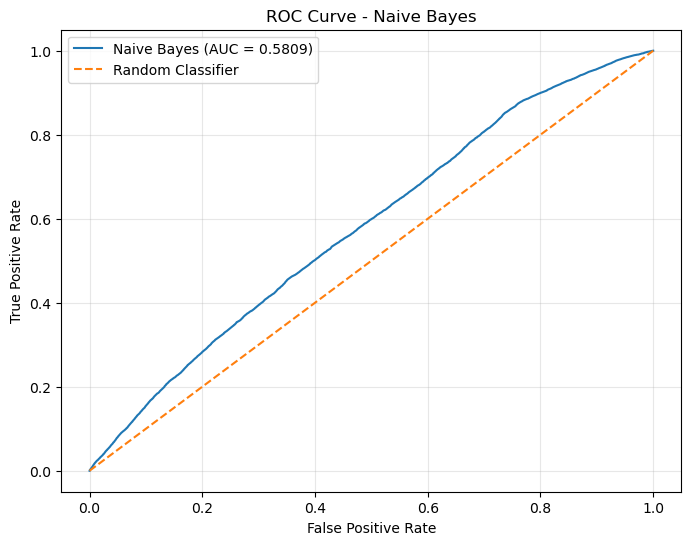

ROC-AUC: 0.5809


In [70]:
# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test_binary, bike_prob)
roc_auc = roc_auc_score(y_test_binary, bike_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Naive Bayes (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")

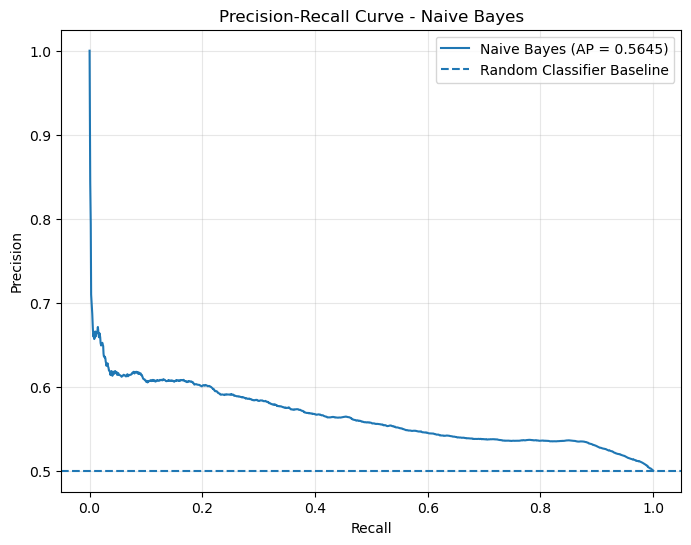

Average Precision: 0.5645


In [71]:
# Calculate Precision-Recall curve and Average Precision
precision, recall, thresholds = precision_recall_curve(
    y_test_binary, bike_prob
)

avg_precision = average_precision_score(y_test_binary, bike_prob)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision,
         label=f"Naive Bayes (AP = {avg_precision:.4f})")

plt.axhline(
    y=y_test_binary.mean(),
    linestyle="--",
    label="Random Classifier Baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Naive Bayes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Average Precision: {avg_precision:.4f}")

<a id="sec-8-5"></a>

### 8.5 Model 2: Logistic Regression
Each predictor is one-hot encoded, so the model learns a separate weight for every hour, weekday, month and season and does not assume a linear trend in, for example, `hour`.

In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Treat all five predictors as categorical
categorical_features = [
    "hour",
    "day_of_week",
    "is_weekend",
    "month",
    "season"
]

# One-hot encode the predictors
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Create the Logistic Regression pipeline
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Train on the same training split used for Naive Bayes
lr_model.fit(X_train, y_train)

# Generate predictions
lr_pred = lr_model.predict(X_test)

print("Logistic Regression training complete!")

Logistic Regression training complete!


In [73]:
# Accuracy
lr_accuracy = accuracy_score(y_test, lr_pred)

print(f"Accuracy: {lr_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

Accuracy: 0.5597

Classification Report:
              precision    recall  f1-score   support

        bike       0.55      0.70      0.61     24000
        taxi       0.58      0.42      0.49     24000

    accuracy                           0.56     48000
   macro avg       0.57      0.56      0.55     48000
weighted avg       0.57      0.56      0.55     48000


Confusion Matrix:
[[16849  7151]
 [13981 10019]]


<a id="sec-8-6"></a>

### 8.6 Model Comparison

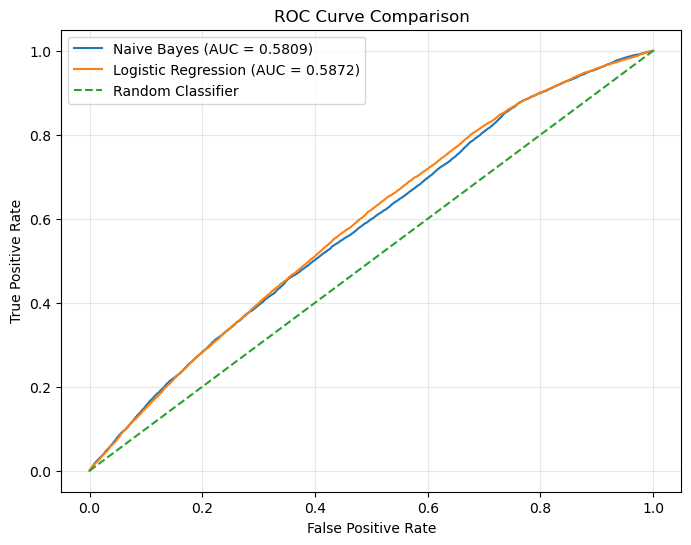

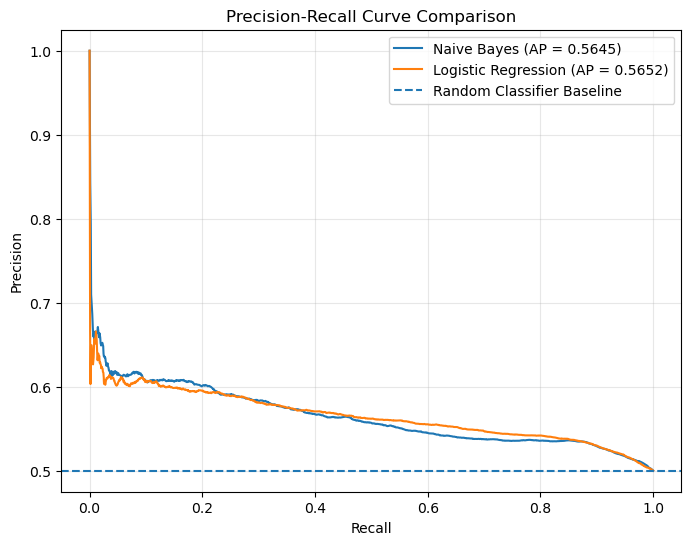

Naive Bayes Accuracy:       0.5480
Logistic Regression Accuracy: 0.5597

Naive Bayes ROC-AUC:        0.5809
Logistic Regression ROC-AUC:  0.5872

Naive Bayes Average Precision: 0.5645
Logistic Regression Average Precision: 0.5652


In [74]:
# Logistic Regression probabilities
lr_prob = lr_model.predict_proba(X_test)

# Find probability column for bike
lr_bike_index = list(lr_model.classes_).index("bike")
lr_bike_prob = lr_prob[:, lr_bike_index]

# Calculate ROC metrics
lr_fpr, lr_tpr, _ = roc_curve(y_test_binary, lr_bike_prob)
lr_auc = roc_auc_score(y_test_binary, lr_bike_prob)

# Calculate PR metrics
lr_precision, lr_recall, _ = precision_recall_curve(
    y_test_binary, lr_bike_prob
)
lr_ap = average_precision_score(y_test_binary, lr_bike_prob)

# ROC comparison
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Naive Bayes (AUC = {roc_auc:.4f})")
plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {lr_auc:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# PR comparison
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f"Naive Bayes (AP = {avg_precision:.4f})")
plt.plot(lr_recall, lr_precision, label=f"Logistic Regression (AP = {lr_ap:.4f})")
plt.axhline(0.5, linestyle="--", label="Random Classifier Baseline")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Naive Bayes Accuracy:       {accuracy:.4f}")
print(f"Logistic Regression Accuracy: {lr_accuracy:.4f}")
print()
print(f"Naive Bayes ROC-AUC:        {roc_auc:.4f}")
print(f"Logistic Regression ROC-AUC:  {lr_auc:.4f}")
print()
print(f"Naive Bayes Average Precision: {avg_precision:.4f}")
print(f"Logistic Regression Average Precision: {lr_ap:.4f}")

| Metric (test set, n = 48,000) | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | 0.5480 | **0.5597** |
| ROC-AUC | 0.5809 | **0.5872** |
| Average Precision | 0.5645 | **0.5652** |

**Interpretation:** Logistic regression performs slightly better on every metric, but both models are only modestly better than random guessing (0.50 accuracy, 0.50 AUC). Time of day, day of week and season alone carry limited signal for separating taxi from bike trips. Both models also predict `bike` more often than `taxi` (bike recall ≈ 0.68–0.70 vs. taxi recall ≈ 0.42). Logistic regression is the model whose predictions are stored in Section 9.

---
<a id="sec-9"></a>

## 9. Storing Predictions in the Database
<sub>[↑ Back to contents](#contents)</sub>
The logistic-regression predictions for the 48,000 test trips are written back to PostgreSQL. This lets the database record each prediction together with the exact feature values it was based on.

<a id="sec-9-1"></a>

### 9.1 Preparing the Prediction Export
Attaches each test trip's original feature values, predicted mode and class probabilities. This cell does not write to the database.

In [75]:
# 1. Original (unencoded) feature values for the test observations
test_export = df.loc[
    X_test.index,
    ["trip_id", "hour", "day_of_week", "is_weekend", "month", "season"]
].copy()

# 2. Add model predictions and probabilities
test_export["predicted_mode"] = lr_pred

probabilities = lr_model.predict_proba(X_test)

bike_index = list(lr_model.classes_).index("bike")
taxi_index = list(lr_model.classes_).index("taxi")

test_export["bike_probability"] = probabilities[:, bike_index]
test_export["taxi_probability"] = probabilities[:, taxi_index]

# 3. Verify the export before inserting
print("Records to insert:", len(test_export))
print("Unique trip IDs:", test_export["trip_id"].nunique())

display(test_export.head())

Records to insert: 48000
Unique trip IDs: 48000


,trip_id,hour,day_of_week,is_weekend,month,season,predicted_mode,bike_probability,taxi_probability
140471,140472,22,2,False,4,Spring,taxi,0.344584,0.655416
157555,157556,22,4,False,8,Summer,taxi,0.330609,0.669391
78029,78030,16,0,True,8,Summer,bike,0.562495,0.437505
142257,142258,19,6,True,4,Spring,taxi,0.482599,0.517401
162025,162026,12,0,True,6,Summer,bike,0.512675,0.487325


<a id="sec-9-2"></a>

### 9.2 Inserting Predictions (One-Time Operation)

> ⚠️ **ONE-TIME OPERATION. Do not rerun.**
> This cell writes to the **permanent** `prediction` and `prediction_feature` tables. It has **already been executed successfully**, and the output below is from that original run.
>
> The insert is guarded by `RUN_PREDICTION_INSERT`, which is set to `False`. With the flag off, running the cell (including via *Run All*) only prints a message and does not touch the database. Set it to `True` **only** if those tables are empty, for example after rebuilding the schema with `Transportation_Database.sql`.
>
> A rerun inserts a second set of `prediction` rows, and the join on `trip_id` then tries to re-insert existing `(prediction_id, feature_id)` pairs into `prediction_feature`, which raises a duplicate-key error. Because everything runs inside a single transaction (`engine.begin()`), a failed rerun is rolled back and leaves the existing records unchanged.

The insert works in three steps inside one transaction:
1. Load the predictions into a **temporary** table (`ON COMMIT DROP`).
2. `INSERT … SELECT` one row per trip into `prediction`.
3. Unpivot the five feature values with `CROSS JOIN LATERAL (VALUES …)` and insert them into `prediction_feature`, which uses the same row-oriented design as `trip_feature`.

In [77]:
from sqlalchemy import text

RUN_PREDICTION_INSERT = False  # Change to True only when intentionally rebuilding predictions

if RUN_PREDICTION_INSERT:
    with engine.begin() as conn:

        conn.execute(text("""
            CREATE TEMP TABLE prediction_staging (
                trip_id BIGINT,
                hour INTEGER,
                day_of_week INTEGER,
                is_weekend BOOLEAN,
                month INTEGER,
                season TEXT,
                predicted_mode VARCHAR(10),
                bike_probability DOUBLE PRECISION,
                taxi_probability DOUBLE PRECISION
            ) ON COMMIT DROP;
        """))

        test_export.to_sql(
            "prediction_staging",
            conn,
            if_exists="append",
            index=False,
            chunksize=5000
        )

        conn.execute(text("""
            INSERT INTO prediction (
                trip_id,
                prediction_time,
                predicted_mode,
                bike_probability,
                taxi_probability
            )
            SELECT
                trip_id,
                CURRENT_TIMESTAMP,
                predicted_mode,
                bike_probability,
                taxi_probability
            FROM prediction_staging;
        """))

        conn.execute(text("""
            INSERT INTO prediction_feature (
                prediction_id,
                feature_id,
                feature_value
            )
            SELECT
                p.prediction_id,
                f.feature_id,
                v.feature_value
            FROM prediction_staging s
            JOIN prediction p
                ON p.trip_id = s.trip_id
            CROSS JOIN LATERAL (
                VALUES
                    ('hour', s.hour::TEXT),
                    ('day_of_week', s.day_of_week::TEXT),
                    ('is_weekend', s.is_weekend::TEXT),
                    ('month', s.month::TEXT),
                    ('season', s.season)
            ) AS v(feature_name, feature_value)
            JOIN feature f
                ON f.feature_name = v.feature_name;
        """))

    print("Predictions and prediction features successfully stored!")

else:
    print("Prediction insertion skipped. Existing database records were preserved.")

Predictions and prediction features successfully stored!


<a id="sec-9-3"></a>

### 9.3 Verifying the Stored Predictions
A read-only check of the row counts in the prediction tables. Expected: **48,000** rows in `prediction` (one per test trip) and **240,000** in `prediction_feature` (5 features × 48,000). These counts also confirm that no duplicate predictions were inserted.

In [78]:
from sqlalchemy import text

with engine.connect() as conn:
    results = conn.execute(text("""
        SELECT 'prediction' AS table_name, COUNT(*) AS record_count
        FROM prediction

        UNION ALL

        SELECT 'prediction_feature', COUNT(*)
        FROM prediction_feature

        UNION ALL

        SELECT 'prediction_audit', COUNT(*)
        FROM prediction_audit;
    """))

    for row in results:
        print(row.table_name, row.record_count)

prediction_audit 48000
prediction 48000
prediction_feature 240000


---
<a id="sec-10"></a>

## 10. Summary
<sub>[↑ Back to contents](#contents)</sub>
- **Data:** 240,000 trips from 2024 (120,000 Yellow Taxi + 120,000 Citi Bike), sampled at 10,000 per month per source.
- **Database:** Raw samples are loaded into staging tables, then normalized into a schema with a shared `trip` supertype, mode-specific `taxi` and `bike` subtypes, and dimension tables for time, stations and user types.
- **Feature store:** The materialized wide table returned identical features about 2.8× faster than the row-oriented table (1.61 s vs. 4.51 s).
- **Modeling:** Logistic regression (accuracy 0.560, ROC-AUC 0.587) slightly outperformed Categorical Naive Bayes (accuracy 0.548, ROC-AUC 0.581). Time-based features alone are weak predictors of trip mode.
- **Prediction storage:** 48,000 predictions and their 240,000 associated feature values (5 per prediction) were stored in `prediction` and `prediction_feature`.